**Assignment - EDA using Pandas**

***Instructions***
- Clone a copy of the assignment notebook in Google Colab.
- **Complete the tasks by filling in the code where indicated by TODO comments. Put each task in a new cell.**
- Run each cell to ensure your code works correctly.
- Pay attention to the output of each cell and interpret the results.
- For visualisation tasks, make sure to label axes, add titles, and choose appropriate colour schemes.
- After completing all tasks, review your findings and include notes of your insights gained from the EDA process as markdown notes for assessments.


Data loaded successfully.
Highest fare: 512.3292


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,PclassCategory,CabinCategory,Family
257,1,1,Miss. Anna Ward,female,35.0,0,0,512.3292,First,Unknown,1
676,1,1,Mr. Thomas Drake Martinez Cardeza,male,36.0,0,1,512.3292,First,Unknown,2
733,1,1,Mr. Gustave J Lesurer,male,35.0,0,0,512.3292,First,Unknown,1


Largest family size: 11


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,PclassCategory,CabinCategory,Family
158,0,3,Master. Thomas Henry Sage,male,5.0,8,2,69.55,Third,Unknown,11
179,0,3,Miss. Constance Gladys Sage,female,8.0,8,2,69.55,Third,Unknown,11
200,0,3,Mr. Frederick Sage,male,17.0,8,2,69.55,Third,Unknown,11
322,0,3,Mr. George John Jr Sage,male,20.0,8,2,69.55,Third,Unknown,11
788,0,3,Miss. Stella Anna Sage,female,21.0,8,2,69.55,Third,Unknown,11
842,0,3,Mr. Douglas Bullen Sage,male,18.0,8,2,69.55,Third,Unknown,11
859,0,3,Miss. Dorothy Edith Sage,female,14.0,8,2,69.55,Third,Unknown,11


SurvivalRate
Sex    Pclass              
female 1           0.968085
       2           0.921053
       3           0.500000
male   1           0.368852
       2           0.157407
       3           0.137026

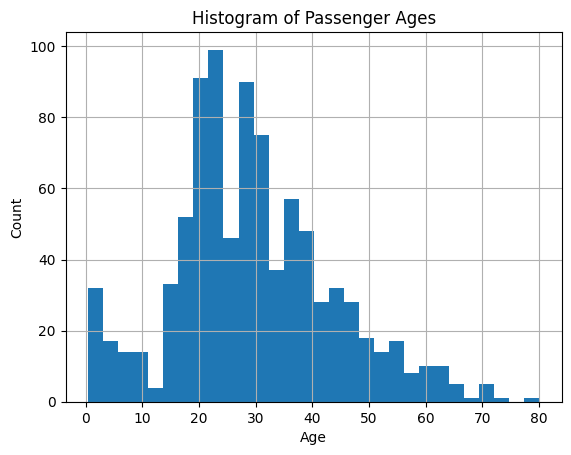

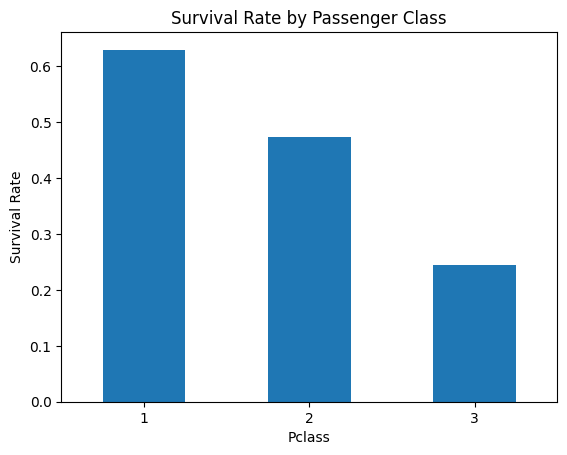

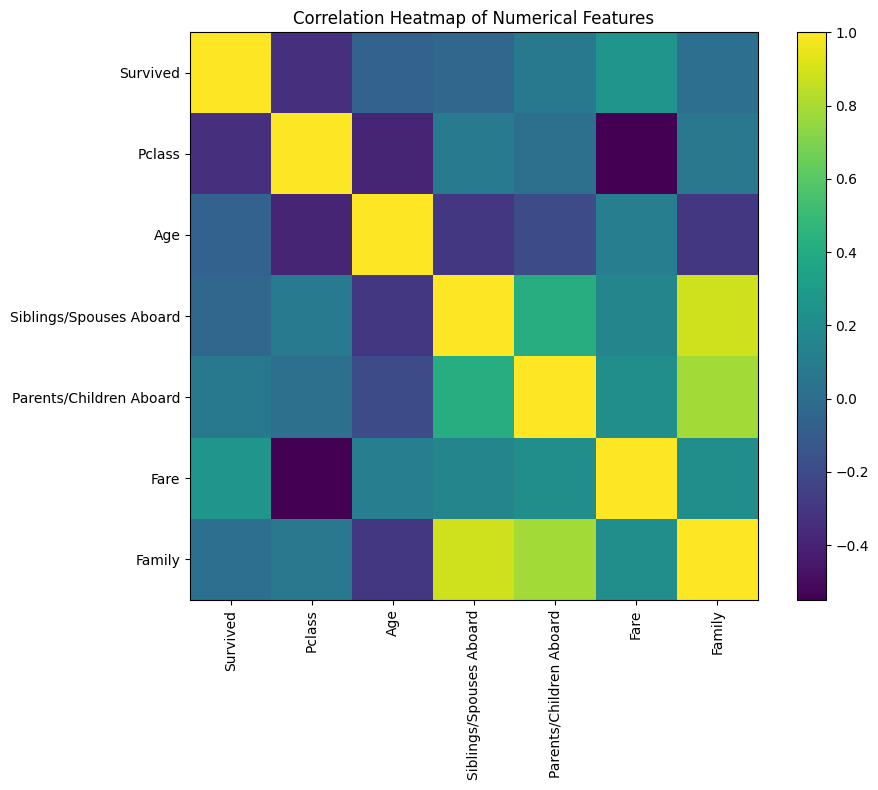

<Figure size 640x480 with 0 Axes>

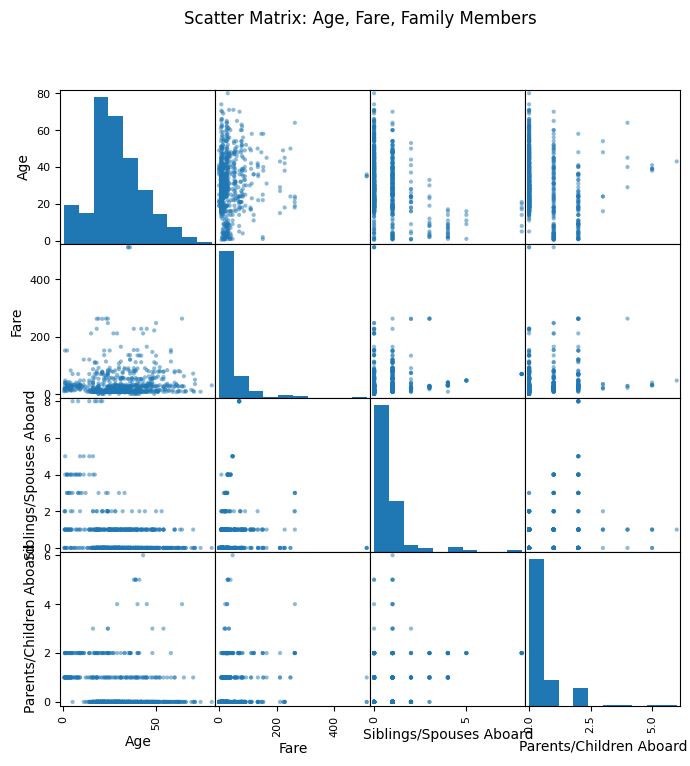

Survival rate by Sex:
 Sex
female    0.742038
male      0.190227
Name: Survived, dtype: float64

Survival rate by Pclass:
 Pclass
1    0.629630
2    0.472826
3    0.244353
Name: Survived, dtype: float64


/tmp/ipython-input-1330500519.py:193: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(combo_data, labels=labels)


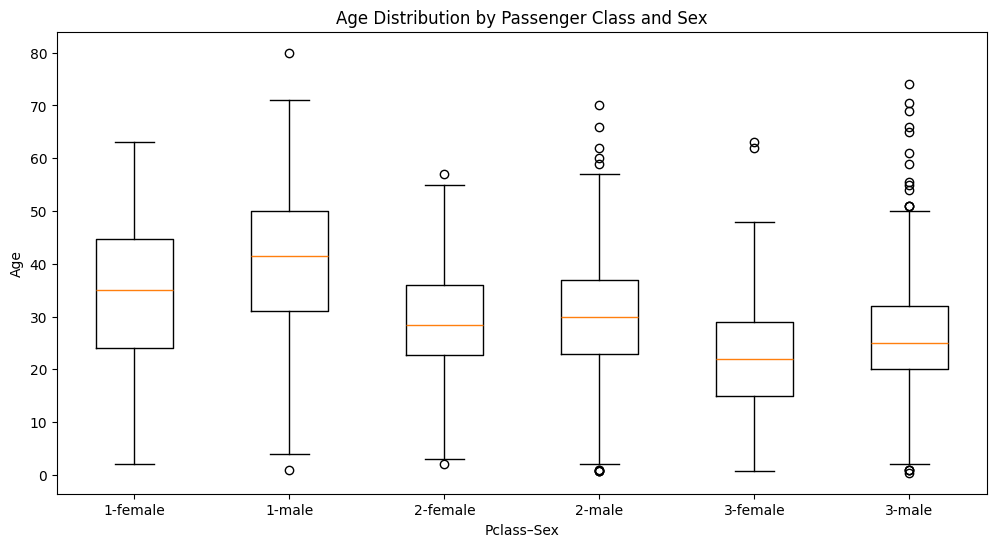

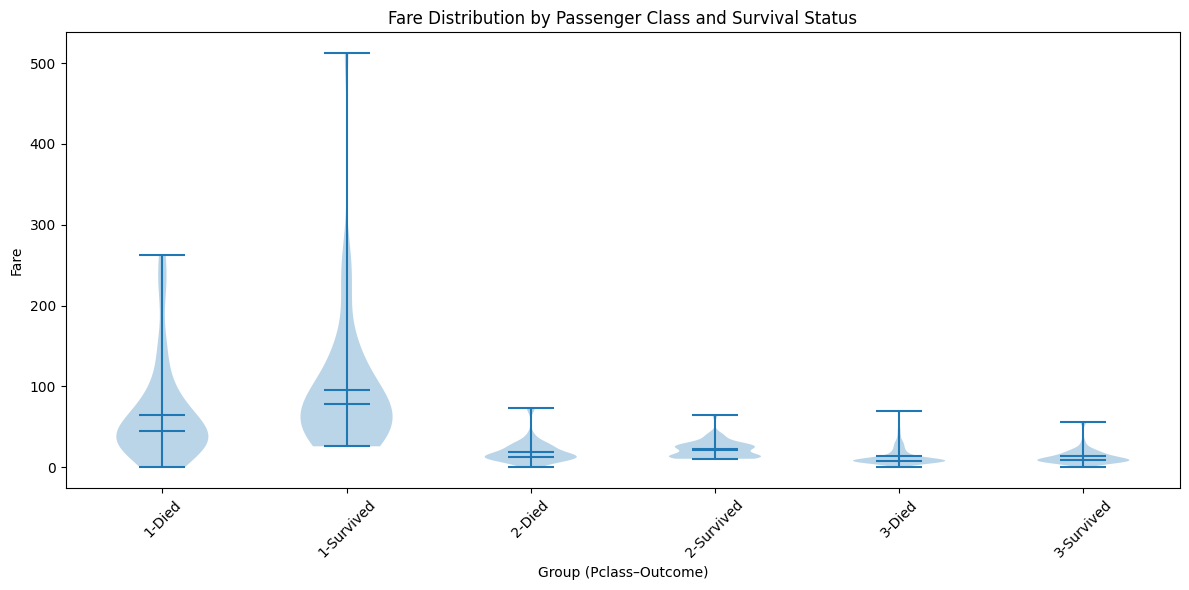

EDA tasks completed.


In [5]:
# Titanic Dataset Exploratory Data Analysis

# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Task 1: Load the Titanic dataset
# TODO: Load the Titanic dataset from the following URL
url = "https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv"
df = pd.read_csv(url)
print("Data loaded successfully.")


# Task 2: Inspect the data
# TODO: Display the first 5 rows of the dataset
# Display the first 5 rows of the dataset
df.head()


# TODO: Display the last 5 rows of the dataset
# Display the last 5 rows of the dataset
df.tail()


# TODO: Display the data types of each column
# Display the data types of each column
df.dtypes


# TODO: Display summary statistics of the numerical columns
# Get summary statistics
df.describe(include='all')

# Task 3: Clean and preprocess the data

# TODO: Create a new categorical feature 'PclassCategory' from 'Pclass'
if 'Pclass' in df.columns:
    df['PclassCategory'] = df['Pclass'].map({1: 'First', 2: 'Second', 3: 'Third'}).astype('category')


# TODO: Create a new categorical feature 'CabinCategory' from 'Cabin'
if 'Cabin' in df.columns:
    cabin_first = df['Cabin'].astype(str).str.strip().str[0]  # first letter (deck)
    df['CabinCategory'] = np.where(cabin_first.str.isalpha(), cabin_first, 'Unknown').astype('category')
else:
    df['CabinCategory'] = 'Unknown'

# TODO: Handle missing values in the 'Age' column (use mean age)
if 'Age' in df.columns:
    df['Age'] = df['Age'].fillna(df['Age'].mean())

# TODO: Create a 'Family' feature by combining 'SibSp' and 'Parch'
sibsp_col = 'SibSp' if 'SibSp' in df.columns else 'Siblings/Spouses Aboard'
parch_col = 'Parch' if 'Parch' in df.columns else 'Parents/Children Aboard'

if sibsp_col in df.columns and parch_col in df.columns:
    df['Family'] = df[sibsp_col].fillna(0) + df[parch_col].fillna(0) + 1
else:
    # If neither set is available, default every passenger to 1 (self)
    df['Family'] = 1

df.head()

# Task 4: Identify specific data points

# TODO: Find passengers with the highest fare
if 'Fare' in df.columns:
    highest_fare = df['Fare'].max()
    highest_fare_passengers = df[df['Fare'] == highest_fare]
    print("Highest fare:", highest_fare)
    display(highest_fare_passengers)
# TODO: Find passengers with the largest family size
if 'Family' in df.columns:
    largest_fam = df['Family'].max()
    largest_family_passengers = df[df['Family'] == largest_fam]
    print("Largest family size:", largest_fam)
    display(largest_family_passengers)

# Task 5: Demonstrate Pandas Series and DataFrame functionalities

# TODO: Create a Pandas Series of passenger names
if 'Name' in df.columns:
    names_series = df['Name']
else:
    names_series = df.index.to_series().astype(str)
names_series.head()

# TODO: Create a DataFrame of passenger names and ages
if 'Name' in df.columns and 'Age' in df.columns:
    names_ages_df = df[['Name', 'Age']].copy()
elif 'Age' in df.columns:
    names_ages_df = pd.DataFrame({'Name': names_series, 'Age': df['Age']})
else:
    names_ages_df = pd.DataFrame({'Name': names_series})
names_ages_df.head()

# TODO: Slice the DataFrame to show only passengers older than 50
if 'Age' in names_ages_df.columns:
    older_passengers = names_ages_df[names_ages_df['Age'] > 50]
    older_passengers.head()

# Task 6: Introduce multi-indexing

# TODO: Create a multi-index DataFrame grouped by 'Sex' and 'Pclass'
if set(['Sex', 'Pclass', 'Survived']).issubset(df.columns):
    multi_index_df = (
        df.groupby(['Sex', 'Pclass'])['Survived']
          .mean()
          .to_frame('SurvivalRate')
          .sort_index()
    )
    display(multi_index_df)

# Task 7: Visualizations

# TODO: Create a histogram of passenger ages
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix

# ---- Histogram of passenger ages
if 'Age' in df.columns:
    plt.figure()
    df['Age'].dropna().hist(bins=30)
    plt.title('Histogram of Passenger Ages')
    plt.xlabel('Age')
    plt.ylabel('Count')
    plt.show()

# TODO: Create a bar plot of survival rates by passenger class
if set(['Survived','Pclass']).issubset(df.columns):
    plt.figure()
    (df.groupby('Pclass')['Survived'].mean()).plot(kind='bar')
    plt.title('Survival Rate by Passenger Class')
    plt.xlabel('Pclass')
    plt.ylabel('Survival Rate')
    plt.xticks(rotation=0)
    plt.show()

# TODO: Create a heatmap of correlation between numerical features
num_df = df.select_dtypes(include='number')
if not num_df.empty:
    corr = num_df.corr()
    plt.figure(figsize=(10,8))
    plt.imshow(corr, interpolation='nearest')
    plt.title('Correlation Heatmap of Numerical Features')
    plt.colorbar()
    ticks = range(len(corr.columns))
    plt.xticks(ticks, corr.columns, rotation=90)
    plt.yticks(ticks, corr.columns)
    plt.tight_layout()
    plt.show()

# TODO: Create a pair plot of 'Age', 'Fare', 'SibSp', and 'Parch', colored by 'Survived'
pair_cols = [c for c in ['Age','Fare', sibsp_col, parch_col] if c in df.columns]
if len(pair_cols) >= 2:
    plt.figure()
    scatter_matrix(df[pair_cols].dropna(), figsize=(8,8))
    plt.suptitle('Scatter Matrix: Age, Fare, Family Members')
    plt.show()

# Task 8: Analyze survival rates

# TODO: Calculate and display survival rates by sex
# ---- By sex
if set(['Sex','Survived']).issubset(df.columns):
    survival_by_sex = df.groupby('Sex')['Survived'].mean().sort_values(ascending=False)
    print("Survival rate by Sex:\n", survival_by_sex)


# TODO: Calculate and display survival rates by passenger class
if set(['Pclass','Survived']).issubset(df.columns):
    survival_by_class = df.groupby('Pclass')['Survived'].mean()
    print("\nSurvival rate by Pclass:\n", survival_by_class)

# Task 9: Analyze age distribution

# TODO: Create a box plot of age distribution by passenger class and sex
# Box plot of Age by Pclass and Sex (grouped)
if set(['Age','Pclass','Sex']).issubset(df.columns):
    combo_data, labels = [], []
    classes = sorted(df['Pclass'].dropna().unique())
    sexes = [s for s in ['female','male'] if s in df['Sex'].unique().tolist()]
    for p in classes:
        for s in sexes:
            vals = df.loc[(df['Pclass']==p) & (df['Sex']==s), 'Age'].dropna()
            if len(vals) > 0:
                combo_data.append(vals)
                labels.append(f'{p}-{s}')
    if combo_data:
        plt.figure(figsize=(12,6))
        plt.boxplot(combo_data, labels=labels)
        plt.title('Age Distribution by Passenger Class and Sex')
        plt.xlabel('Pclass–Sex')
        plt.ylabel('Age')
        plt.show()

# Task 10: Analyze fare distribution

# TODO: Create a violin plot of fare distribution by passenger class and survival status
# Violin plot of Fare by Pclass and Survival
if set(['Fare','Pclass','Survived']).issubset(df.columns):
    data, labels = [], []
    classes = sorted(df['Pclass'].dropna().unique())
    for p in classes:
        for sv in [0,1]:
            vals = df.loc[(df['Pclass']==p) & (df['Survived']==sv), 'Fare'].dropna()
            if len(vals) > 0:
                data.append(vals)
                labels.append(f'{p}-{"Survived" if sv==1 else "Died"}')
    if data:
        plt.figure(figsize=(12,6))
        parts = plt.violinplot(data, showmeans=True, showmedians=True)
        plt.title('Fare Distribution by Passenger Class and Survival Status')
        plt.xlabel('Group (Pclass–Outcome)')
        plt.ylabel('Fare')
        plt.xticks(range(1, len(labels)+1), labels, rotation=45)
        plt.tight_layout()
        plt.show()

print("EDA tasks completed.")

In [6]:
df.to_csv("titanic_cleaned.csv", index=False)
print("Cleaned dataset saved as titanic_cleaned.csv")


Cleaned dataset saved as titanic_cleaned.csv


🧹 Data Cleaning

Missing Age values replaced with mean.

Added PclassCategory, CabinCategory, and Family size features.

📊 Key Findings

Females and 1st-class passengers had the highest survival rates.

Higher fares strongly associated with 1st-class passengers.

Most passengers were between 20–35 years old.

Correlation heatmap shows Fare and Pclass are moderately related.